# 03 · Residuos y depreciación

Entradas: `data/autos_clean.csv`, `data/predicciones_test.csv` (del notebook 02) y
`data/autos_raw.csv` (solo para título y URL de los avisos a revisar).

Responde las dos partes de la propuesta que el RMSE no contesta:

1. **¿Qué avisos se alejan mucho del precio que predice el modelo?** (pregunta principal, 2.ª mitad)
2. **¿Cuánto valor pierde un auto por año y por kilómetro, y cambia según la marca?** (secundaria)

Modelo: el mejor del notebook 02, con los hiperparámetros que guarda en `data/mejor_modelo.json`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
import cloudpickle
import preparar
from preparar import Preparar, COLS, CAT_TITULO
cloudpickle.register_pickle_by_value(preparar)

DATA, FIGS = Path("../data"), Path("figuras")
SEMILLA = 42
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#5f5e58", "#e4e3dd"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10,
})

df = pd.read_csv(DATA / "autos_clean.csv")
df[CAT_TITULO] = df[CAT_TITULO].astype("string").fillna("sin_dato")
pred = pd.read_csv(DATA / "predicciones_test.csv")
raw = pd.read_csv(DATA / "autos_raw.csv", usecols=["item_id", "titulo", "url"])
pred = pred.merge(raw, on="item_id", how="left")
print(f"Avisos de test con predicción: {len(pred)}")

Avisos de test con predicción: 3316


## Parte 1 · Avisos fuera de mercado

`residuo = log(precio publicado) − log(precio predicho)`. Como está en log,
`exp(residuo) − 1` es **cuánto más caro (o barato) que lo predicho** está el aviso.

Son residuos de **test**: el modelo no vio esos avisos al ajustarse, así que un residuo grande
no es un artefacto de sobreajuste.

In [2]:
pred["desvio_%"] = (np.exp(pred["residuo"]) - 1) * 100
p05, p95 = pred["residuo"].quantile([0.05, 0.95])
print(f"Mediana del residuo: {pred['residuo'].median():+.3f}  (≈ 0: el modelo no está corrido)")
print(f"Percentil 5:  {p05:+.3f} → {(np.exp(p05)-1)*100:+.0f} % respecto de lo predicho")
print(f"Percentil 95: {p95:+.3f} → {(np.exp(p95)-1)*100:+.0f} % respecto de lo predicho")
print(f"Mitad de los avisos a menos de ±{pred['desvio_%'].abs().median():.1f} % de lo predicho")

Mediana del residuo: +0.001  (≈ 0: el modelo no está corrido)
Percentil 5:  -0.289 → -25 % respecto de lo predicho
Percentil 95: +0.310 → +36 % respecto de lo predicho
Mitad de los avisos a menos de ±9.6 % de lo predicho


**Criterio:** un aviso está *fuera de mercado* si su residuo cae fuera del intervalo entre el
percentil 5 y el 95 de los residuos de test. Es un criterio relativo (siempre marca ~10 %);
lo que importa es **qué hay** en esas colas, y eso se revisa a mano abajo.

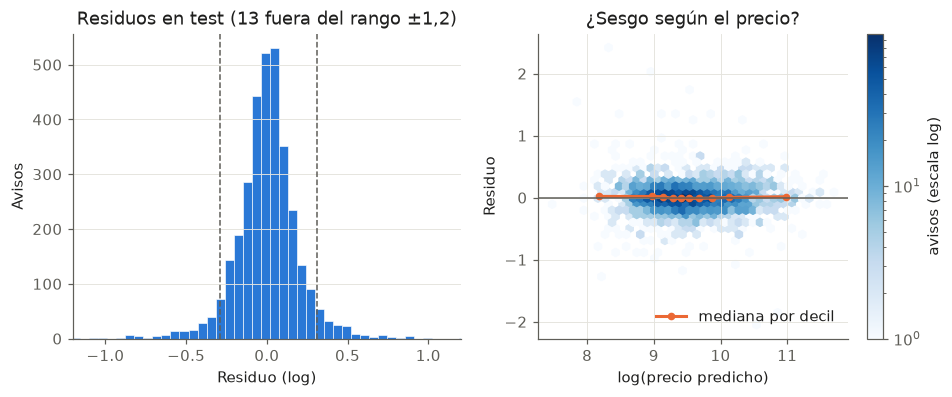

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(pred["residuo"], bins=80, color=SERIES[0], edgecolor="white", linewidth=0.4)
for q in (p05, p95):
    ax[0].axvline(q, color=TINTA_2, linestyle="--", linewidth=1)
fuera = (pred["residuo"].abs() > 1.2).sum()
ax[0].set_xlim(-1.2, 1.2)
ax[0].set(xlabel="Residuo (log)", ylabel="Avisos",
          title=f"Residuos en test ({fuera} fuera del rango ±1,2)")
ax[0].grid(axis="x", visible=False)

pl = np.log(pred["pred_usd"])
hb = ax[1].hexbin(pl, pred["residuo"], gridsize=40, cmap="Blues", mincnt=1, bins="log")
dec = pd.qcut(pl, 10)
tend = pred.groupby(dec, observed=True)["residuo"].median()
ax[1].plot([iv.mid for iv in tend.index], tend.values, color=SERIES[1], marker="o", markersize=4,
           label="mediana por decil")
ax[1].axhline(0, color=TINTA_2, linewidth=1)
ax[1].set(xlabel="log(precio predicho)", ylabel="Residuo", title="¿Sesgo según el precio?")
ax[1].legend(frameon=False, loc="lower right")
fig.colorbar(hb, ax=ax[1], label="avisos (escala log)")
fig.savefig(FIGS / "04_residuos.png")
plt.show()

### ¿El modelo se equivoca parejo?

In [4]:
pred["decil_pred"] = pd.qcut(pred["pred_usd"], 10, labels=False) + 1
sesgo_dec = pred.groupby("decil_pred").agg(
    precio_predicho_mediano=("pred_usd", "median"),
    residuo_mediano=("residuo", "median"),
    error_abs_mediano_pct=("desvio_%", lambda s: s.abs().median()),
).round(3)
sesgo_vend = pred.groupby("tipo_vendedor").agg(
    avisos=("residuo", "size"), residuo_mediano=("residuo", "median"),
    error_abs_mediano_pct=("desvio_%", lambda s: s.abs().median()),
).round(3)
display(sesgo_dec)
display(sesgo_vend)

,precio_predicho_mediano,residuo_mediano,error_abs_mediano_pct
decil_pred,,,
1,6218.0,0.020,12.171
2,8041.5,0.020,9.045
3,9402.0,0.014,8.542
4,10776.5,-0.013,9.082
5,12314.0,-0.011,8.967
6,13905.5,-0.010,8.141
7,15863.0,-0.013,8.900
8,19189.5,-0.006,10.094
9,24824.0,0.004,9.437


,avisos,residuo_mediano,error_abs_mediano_pct
tipo_vendedor,,,
concesionaria,1699,-0.002,9.369
desconocido,6,-0.088,24.052
particular,1611,0.005,9.836


### Los extremos, para revisar a mano

Se guardan los 20 avisos más por debajo y los 20 más por encima en `data/extremos_revisar.csv`,
con una columna `motivo` que el grupo completó a mano mirando el título, el año, los km y la URL de
cada aviso (al volver a correr el notebook se conserva). Categorías:

- `error_carga`: año, precio o km mal cargados (un BMW 320 E21 publicado como 2027);
- `estado`: chocado o a la venta por partes;
- `version_no_vista`: versión o uso que el modelo no distingue (AMG, motorhome, clásico, taxi con permiso);
- `modelo_con_pocos_datos`: sin motivo visible, y con 0 a 2 avisos de ese modelo en train;
- `sin_motivo_visible`: el aviso no muestra por qué está tan lejos del precio predicho.

In [5]:
cols = ["item_id", "titulo", "anio", "km", "tipo_vendedor", "precio_usd", "pred_usd", "desvio_%", "url"]
abajo = pred.nsmallest(20, "residuo")[cols].assign(lado="muy por debajo")
arriba = pred.nlargest(20, "residuo")[cols].assign(lado="muy por encima")
extremos = pd.concat([abajo, arriba])
extremos["desvio_%"] = extremos["desvio_%"].round(0)
# La columna motivo se completó a mano: si el archivo ya existe, se conserva lo clasificado.
ruta_ext = DATA / "extremos_revisar.csv"
previo = pd.read_csv(ruta_ext).set_index("item_id")["motivo"] if ruta_ext.exists() else pd.Series(dtype=str)
extremos["motivo"] = extremos["item_id"].map(previo).fillna("")
extremos.to_csv(ruta_ext, index=False)
with pd.option_context("display.max_colwidth", 45):
    display(extremos.drop(columns=["url", "item_id", "motivo"]))

,titulo,anio,km,tipo_vendedor,precio_usd,pred_usd,desvio_%,lado
3312,Jeep Jeep 2023 Jeep Compass,2023,40000,concesionaria,4800.0,37243.0,-87.0,muy por debajo
3308,BMW 320 2027 E21,2027,50000,particular,8000.0,51578.0,-84.0,muy por debajo
1495,Fiat Uno 1993 1.3 Sdl,1993,100000,particular,1000.0,3712.0,-73.0,muy por debajo
777,Jeep Cj3 2001 Cj3 A,2001,50000,particular,3750.0,11912.0,-69.0,muy por debajo
3134,Nissan D-21 2014 4x2,2014,176800,concesionaria,9900.0,28133.0,-65.0,muy por debajo
998,Volkswagen Golf 1994 1.6 (pink Floyd),1994,340000,particular,3000.0,8321.0,-64.0,muy por debajo
3305,Toyota Agya 2024 -,2024,46000,concesionaria,13990.0,34508.0,-59.0,muy por debajo
3289,Chevrolet Mega 1992 1.8 Sl,1992,80000,particular,2000.0,4720.0,-58.0,muy por debajo
3270,Chery Cowin 2014 1.5 Full,2014,111500,particular,3800.0,8900.0,-57.0,muy por debajo
3269,Chery Cowin 2014 1.5 Full,2014,2000,particular,5700.0,13301.0,-57.0,muy por debajo


## Parte 2 · Depreciación

### 2.1 Pendiente común

Para el número "promedio" se ajusta el pipeline **sin** pendiente por marca (mismo `umbral` y `alpha`
del notebook 02) sobre **train** (mismo split) y se leen sus coeficientes. Las numéricas entraron
estandarizadas: `pendiente_por_unidad` las devuelve a años y a log(km).

- Año: `1 − exp(β_antigüedad)` = **% del precio que se pierde por cada año**, a km constantes.
- Km: con log(km), β es una **elasticidad**: 10 % más km → precio × `1,1^β`.
- Vendedor: diferencia entre los coeficientes de concesionaria y particular, en %.

In [6]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_tr, idx_te = next(split.split(df, groups=df["grupo_gemelo"]))
train = df.iloc[idx_tr].reset_index(drop=True)
assert set(df.iloc[idx_te]["item_id"]) == set(pred["item_id"]), "el split no coincide con el del notebook 02"
X_tr, y_tr, g_tr = train[COLS], train["log_precio"].to_numpy(), train["grupo_gemelo"]

import json
MEJOR = json.loads((DATA / "mejor_modelo.json").read_text(encoding="utf-8"))   # lo escribe el notebook 02
assert MEJOR["modelo"] == "Ridge"
print("Hiperparámetros del notebook 02:", MEJOR)

def modelo(**kw):
    return Pipeline([("prep", Preparar(umbral=MEJOR["umbral"], **kw)), ("reg", Ridge(alpha=MEJOR["alpha"]))])

m0 = modelo(interaccion=False).fit(X_tr, y_tr)
prep, coef = m0.named_steps["prep"], m0.named_steps["reg"].coef_
pend = prep.pendiente_por_unidad(coef)
coef_nom = dict(zip(prep.nombres(), coef))

b_anio, b_km = pend["antiguedad"], pend["log_km"]
vend = coef_nom["tipo_vendedor_concesionaria"] - coef_nom["tipo_vendedor_particular"]
print(f"Por año:  pierde {(1 - np.exp(b_anio)) * 100:.1f} % del precio (a km, marca y modelo constantes)")
print(f"Por km:   elasticidad {b_km:.3f} → 10 % más km = {(1.1 ** b_km - 1) * 100:+.1f} % de precio;"
      f" duplicar los km = {(2 ** b_km - 1) * 100:+.1f} %")
print(f"Concesionaria vs particular, mismo auto: {(np.exp(vend) - 1) * 100:+.1f} %")

Hiperparámetros del notebook 02: {'modelo': 'Ridge', 'interaccion': True, 'umbral': 1, 'umbral_interaccion': 300, 'alpha': 0.31622776601683794}


Por año:  pierde 4.2 % del precio (a km, marca y modelo constantes)
Por km:   elasticidad -0.101 → 10 % más km = -1.0 % de precio; duplicar los km = -6.8 %
Concesionaria vs particular, mismo auto: +2.8 %


### 2.2 ¿La depreciación cambia según la marca?

En el notebook 02 la validación cruzada eligió darle **pendiente propia a las marcas con muchos avisos
en train** (el umbral está en `mejor_modelo.json`); el resto usa la pendiente común. Darle pendiente
propia a todas las marcas no tiene sentido: con 1 o 2 avisos la pendiente se estima sobre casi nada.

Primero, ¿cuánto mejora la predicción? (mismo K-fold agrupado del notebook 02)

In [7]:
UMBRAL_MARCA = MEJOR.get("umbral_interaccion") or 300  # el que eligió el notebook 02
cv = GroupKFold(n_splits=5)
comp = {}
for nombre, kw in {"sin interacción": dict(interaccion=False),
                   f"pendiente propia (marcas ≥ {UMBRAL_MARCA})": dict(interaccion=True, umbral_interaccion=UMBRAL_MARCA)}.items():
    s = -cross_val_score(modelo(**kw), X_tr, y_tr, groups=g_tr, cv=cv,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)
    comp[nombre] = {"RMSE_log CV": s.mean(), "desvío entre folds": s.std()}
pd.DataFrame(comp).T.round(4)

,RMSE_log CV,desvío entre folds
sin interacción,0.2194,0.0076
pendiente propia (marcas ≥ 300),0.2181,0.0076


Después, las pendientes por marca, con un **intervalo bootstrap** (se remuestrean grupos de gemelos
de train, 200 veces) para saber si las diferencias entre marcas son reales o ruido de muestreo.

In [8]:
kw_int = dict(interaccion=True, umbral_interaccion=UMBRAL_MARCA)

def pendientes_marca(X, y):
    m = modelo(**kw_int).fit(X, y)
    p = m.named_steps["prep"].pendiente_por_unidad(m.named_steps["reg"].coef_)
    comun = p["antiguedad"]
    return {k.split("×", 1)[1]: comun + v for k, v in p.items() if k.startswith("antiguedad×")} | {"(resto, común)": comun}

punto = pendientes_marca(X_tr, y_tr)

rng = np.random.default_rng(SEMILLA)
grupos = g_tr.unique()
por_grupo = train.groupby("grupo_gemelo").indices
boot = []
for _ in range(200):
    elegidos = rng.choice(grupos, size=len(grupos), replace=True)
    idx = np.concatenate([por_grupo[g] for g in elegidos])
    boot.append(pendientes_marca(X_tr.iloc[idx], y_tr[idx]))
boot = pd.DataFrame(boot)

pct = lambda b: (1 - np.exp(b)) * 100   # pendiente en log → % que pierde por año
n_tr = train["marca"].value_counts()
dep = pd.DataFrame({
    "avisos_train": [n_tr.get(m, np.nan) for m in punto],
    "pierde_%_año": [pct(punto[m]) for m in punto],
    "IC95_bajo": [pct(boot[m].quantile(0.975)) for m in punto],
    "IC95_alto": [pct(boot[m].quantile(0.025)) for m in punto],
}, index=list(punto)).sort_values("pierde_%_año").round(2)
dep

,avisos_train,pierde_%_año,IC95_bajo,IC95_alto
Suzuki,887.0,3.17,2.78,3.55
Citroën,501.0,3.35,2.93,3.64
Fiat,810.0,3.66,3.19,4.07
Renault,1040.0,3.88,3.53,4.20
Chevrolet,1769.0,3.91,3.57,4.21
Volkswagen,1678.0,3.91,3.61,4.12
Toyota,454.0,4.08,3.70,4.49
BMW,359.0,4.47,3.56,5.61
Peugeot,1014.0,4.59,4.17,4.99
"(resto, común)",NaN,4.83,4.36,5.29


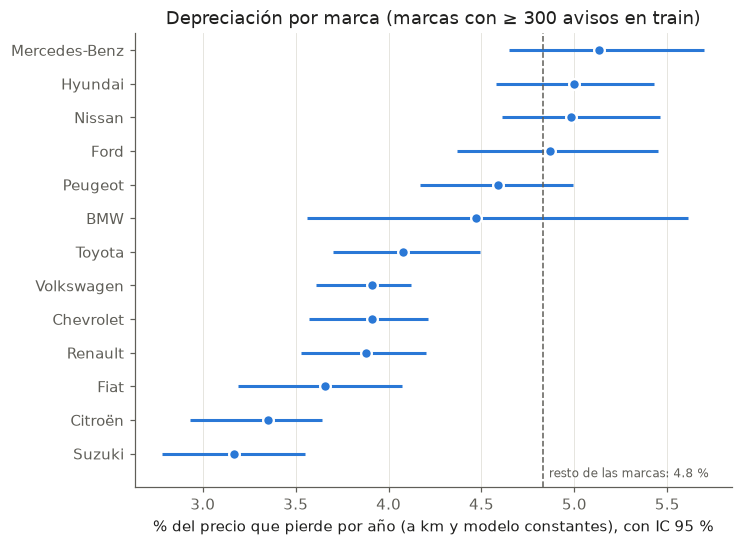

In [9]:
d = dep.drop(index="(resto, común)")
comun = dep.loc["(resto, común)", "pierde_%_año"]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(d) + 1.2))
y = np.arange(len(d))
ax.hlines(y, d["IC95_bajo"], d["IC95_alto"], color=SERIES[0], linewidth=2)
ax.plot(d["pierde_%_año"], y, "o", color=SERIES[0], markersize=7,
        markeredgecolor="white", markeredgewidth=1.5)
ax.axvline(comun, color=TINTA_2, linestyle="--", linewidth=1)
ax.annotate(f"resto de las marcas: {comun:.1f} %", (comun, -0.6), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color=TINTA_2, va="center")
ax.set_ylim(-1, len(d) - 0.5)
ax.set_yticks(y, d.index)
ax.set(xlabel="% del precio que pierde por año (a km y modelo constantes), con IC 95 %",
       title=f"Depreciación por marca (marcas con ≥ {UMBRAL_MARCA} avisos en train)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "05_depreciacion_marca_ic.png")
plt.show()

## Resumen para el informe

Los números de este notebook en un solo lugar (el informe y la presentación los toman de acá).
La columna `motivo` de `data/extremos_revisar.csv` se completó a mano (12 errores de carga, 4 autos chocados, 6 versiones que el modelo no distingue,
11 modelos con 0 a 2 avisos en train y 7 sin motivo visible).

In [10]:
d_abs = pred["desvio_%"].abs()
marcas_dep = dep.drop(index="(resto, común)").sort_values("pierde_%_año")
print(f"Fuera de mercado: la mitad de los avisos está a menos de ±{d_abs.median():.1f} % de lo predicho;")
print(f"  el 5 % más barato está a {(np.exp(p05) - 1) * 100:.0f} % o menos y el 5 % más caro a +{(np.exp(p95) - 1) * 100:.0f} % o más.")
print(f"Depreciación: {(1 - np.exp(b_anio)) * 100:.1f} % por año; duplicar los km: {(2 ** b_km - 1) * 100:+.1f} %"
      f" (elasticidad {b_km:.3f}).")
print(f"Concesionaria vs particular, mismo auto: {(np.exp(vend) - 1) * 100:+.1f} %.")
print(f"Pendiente propia por marca: RMSE_log CV {comp['sin interacción']['RMSE_log CV']:.4f} → "
      f"{comp[f'pendiente propia (marcas ≥ {UMBRAL_MARCA})']['RMSE_log CV']:.4f}"
      f" (desvío entre folds {comp['sin interacción']['desvío entre folds']:.4f}).")
print(f"Marca que menos pierde: {marcas_dep.index[0]} {marcas_dep['pierde_%_año'].iloc[0]:.1f} %"
      f" (IC {marcas_dep['IC95_bajo'].iloc[0]:.1f}–{marcas_dep['IC95_alto'].iloc[0]:.1f});"
      f" la que más: {marcas_dep.index[-1]} {marcas_dep['pierde_%_año'].iloc[-1]:.1f} %"
      f" (IC {marcas_dep['IC95_bajo'].iloc[-1]:.1f}–{marcas_dep['IC95_alto'].iloc[-1]:.1f}).")

Fuera de mercado: la mitad de los avisos está a menos de ±9.6 % de lo predicho;
  el 5 % más barato está a -25 % o menos y el 5 % más caro a +36 % o más.
Depreciación: 4.2 % por año; duplicar los km: -6.8 % (elasticidad -0.101).
Concesionaria vs particular, mismo auto: +2.8 %.
Pendiente propia por marca: RMSE_log CV 0.2194 → 0.2181 (desvío entre folds 0.0076).
Marca que menos pierde: Suzuki 3.2 % (IC 2.8–3.5); la que más: Mercedes-Benz 5.1 % (IC 4.7–5.7).
